# 04. Pesquisa local

Hill Climbing e Simulated Annealing (`src/local_search.py`), a partir da solução do Greedy. O problema e o modelo estão descritos no notebook 01.

In [ ]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import pandas as pd

from collections import Counter

from src.model import load_problem, evaluate, check_solution, plot_routes, plot_gantt, plot_histories
from src.informed import greedy, astar_trips, h_mst, h_relaxed
from src.local_search import hill_climbing, simulated_annealing, neighbours
from src.csp import solve

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 170)
ROOT = Path.cwd().parent
tiny = load_problem(ROOT / "data" / "tiny")
small = load_problem(ROOT / "data" / "small")
PROBLEMS = {"tiny": tiny, "small": small}

optimum = {name: astar_trips(problem, h_relaxed).cost for name, problem in PROBLEMS.items()}   # ótimo provado (notebook 03)
starts = {name: greedy(problem, h_mst).solution for name, problem in PROBLEMS.items()}

In [2]:
# os 18 pedidos do tiny depois do agrupamento
rows = [dict(id=request_id, tipo=request.kind, local=request.loc,
             janela=f"{tiny.clock(request.tw[0])} – {tiny.clock(request.tw[1])}",
             kg=request.weight, linhas=len(request.items), depende_de=", ".join(request.deps))
        for request_id, request in tiny.requests.items()]
pd.DataFrame(rows).set_index("id").T

id,P1,P2,P3,P4,P5,P6,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10,D11,D12
tipo,P,P,P,P,P,P,D,D,D,D,D,D,D,D,D,D,D,D
local,1,1,2,2,3,3,7,8,6,7,5,7,9,6,9,8,5,6
janela,30 09:30 – 30 09:45,31 09:00 – 31 11:15,30 09:00 – 30 10:30,31 08:15 – 31 10:00,30 08:00 – 30 09:45,31 07:45 – 31 09:45,31 10:30 – 31 12:45,31 07:15 – 31 10:15,31 11:30 – 31 14:15,30 11:30 – 30 13:45,31 10:30 – 31 12:30,31 10:45 – 31 13:15,31 10:45 – 31 13:30,31 09:30 – 31 12:00,31 08:15 – 31 09:45,30 11:45 – 30 14:00,30 10:15 – 30 14:00,30 12:15 – 30 14:45
kg,52.0,41.1,77.6,29.9,37.3,32.1,22.0,6.8,21.6,26.3,9.3,16.7,33.5,18.8,36.7,9.2,18.0,51.1
linhas,8,5,9,5,7,6,4,2,4,3,2,2,4,3,5,2,4,5
depende_de,,,,,,,"P2, P4, P6","P1, P5","P2, P4, P6","P1, P3, P5","P4, P6","P4, P6","P2, P4","P3, P5","P1, P3, P5","P1, P3","P1, P3, P5","P1, P3"


## 1. Representação

Uma solução é `{veículo: [viagens]}`. As soluções comparam-se pelo custo penalizado: `km + 100·(atraso + excesso de carga + excesso de permanência) + 10 000·(erros estruturais)`.

## 2. Vizinhança

*relocate* (mudar um pedido de sítio), *swap* (trocar dois pedidos) e *2-opt* (inverter um troço de uma viagem).

In [3]:
for name, problem in PROBLEMS.items():
    moves = list(neighbours(problem, starts[name]))
    move_counts = Counter(move[0] for move, _ in moves)
    feasible = sum(evaluate(problem, neighbour).feasible for _, neighbour in moves)
    print(name, dict(move_counts), "| total:", len(moves), "| viáveis:", feasible)

tiny {'relocate': 210, 'new-trip': 160, 'swap': 81, '2-opt': 18} | total: 469 | viáveis: 46
small {'relocate': 893, 'new-trip': 442, 'swap': 366, '2-opt': 67} | total: 1768 | viáveis: 155


## 3. Hill Climbing

O Hill Climbing passa sempre para um vizinho melhor: o *steepest* escolhe o melhor de todos, o *first improvement* o primeiro que encontra (passos mais baratos). É simples e rápido, mas para no primeiro ótimo local.

In [4]:
hill_climbs = {}
for name, problem in PROBLEMS.items():
    hill_climbs[name, "steepest"] = hill_climbing(problem, starts[name], "steepest")
    for seed in range(5):
        hill_climbs[name, f"first-{seed}"] = hill_climbing(problem, starts[name], "first", seed=seed)
pd.DataFrame([dict(dataset=name, variante=variant, **result.summary())
              for (name, variant), result in hill_climbs.items()])

,dataset,variante,algorithm,initial_km,final_km,improvement_pct,feasible,iterations,evaluated,seconds
0,tiny,steepest,HC-steepest,625.46,533.09,14.77,True,5,2714,0.108
1,tiny,first-0,HC-first,625.46,533.09,14.77,True,5,705,0.041
2,tiny,first-1,HC-first,625.46,533.09,14.77,True,5,1124,0.055
3,tiny,first-2,HC-first,625.46,533.09,14.77,True,5,834,0.047
4,tiny,first-3,HC-first,625.46,533.09,14.77,True,5,856,0.047
5,tiny,first-4,HC-first,625.46,533.09,14.77,True,5,590,0.039
6,small,steepest,HC-steepest,1000.35,799.35,20.09,True,8,15904,1.010
7,small,first-0,HC-first,1000.35,834.22,16.61,True,11,4420,0.482
8,small,first-1,HC-first,1000.35,799.35,20.09,True,14,5230,0.643
9,small,first-2,HC-first,1000.35,825.54,17.47,True,10,2844,0.409


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, PROBLEMS):
    plot_histories({variant: dict(current=result.history) for (dataset, variant), result in hill_climbs.items()
                    if dataset == name}, f"{name}: Hill Climbing", ax=ax)
    ax.axhline(optimum[name], color="grey", ls=":", label="ótimo")
    ax.legend(fontsize=7)

In [6]:
for name in PROBLEMS:
    print(name, "movimentos aceites (steepest):", [move[0] for move in hill_climbs[name, "steepest"].moves])

tiny movimentos aceites (steepest): ['relocate', 'relocate', 'relocate', 'swap', 'relocate']
small movimentos aceites (steepest): ['relocate', 'relocate', 'relocate', 'relocate', 'relocate', 'relocate', 'relocate', 'relocate']


## 4. Simulated Annealing

O Simulated Annealing aceita às vezes vizinhos piores, cada vez com menos probabilidade, para conseguir sair de ótimos locais.

In [ ]:
annealing = {name: simulated_annealing(problem, starts[name], t0=30, alpha=0.9998, iters=30_000, seed=0)
             for name, problem in PROBLEMS.items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, name in zip(axes, PROBLEMS):
    plot_histories({"atual": dict(current=annealing[name].history)}, f"{name}: SA (T0=30, α=0.9998)", ax=ax,
                   cap=optimum[name] * 1.6)
    best_so_far = pd.Series(annealing[name].best_history).replace(float("inf"), None)
    ax.plot(best_so_far.index, best_so_far.values, color="black", lw=1.5, label="melhor viável")
    ax.legend()
pd.DataFrame([dict(dataset=name, **result.summary()) for name, result in annealing.items()])

### Sensibilidade a T₀ e α (small, 3 sementes)

In [8]:
rows = []
for t0 in (5, 30, 100):
    for alpha in (0.999, 0.9995, 0.9998):
        for seed in range(3):
            result = simulated_annealing(small, starts["small"], t0=t0, alpha=alpha, iters=15_000, seed=seed)
            rows.append(dict(T0=t0, alpha=alpha, seed=seed, km=result.cost, viavel=result.feasible,
                             segundos=result.seconds))
sensitivity = pd.DataFrame(rows)
sensitivity.pivot_table(index="T0", columns="alpha", values="km", aggfunc=["mean", "min"]).round(1)

mean                  min              
alpha 0.9990 0.9995 0.9998 0.9990 0.9995 0.9998
T0                                             
5      822.1  818.7  806.1  815.4  815.4  787.7
30     813.5  825.8  797.7  799.4  825.8  771.7
100    813.1  817.8  837.5  787.7  810.5  817.5

## 5. Efeito da solução inicial (small)

In [9]:
csp_start = solve(small, global_fc=True).solution
# solução trivial: um pedido por viagem, por ordem de janela, alternando os veículos
trivial = {vehicle.vid: [] for vehicle in small.vehicles}
for i, request_id in enumerate(sorted(small.requests, key=lambda r: small.requests[r].tw[0])):
    trivial[small.vehicles[i % 2].vid].append([request_id])

rows = []
for label, start in [("Greedy h3", starts["small"]), ("CSP (MAC+MRV+FC global)", csp_start),
                     ("trivial (1 pedido por viagem)", trivial)]:
    initial = evaluate(small, start)
    climb = hill_climbing(small, start, "steepest") if initial.feasible else None
    anneal = simulated_annealing(small, start, t0=30, alpha=0.9998, iters=30_000, seed=0)
    rows.append(dict(inicio=label, km_inicial=round(initial.km, 2), inicial_viavel=initial.feasible,
                     HC_steepest=None if climb is None else round(climb.cost, 2),
                     SA=round(anneal.cost, 2) if anneal.feasible else None))
pd.DataFrame(rows)

,inicio,km_inicial,inicial_viavel,HC_steepest,SA
0,Greedy h3,1000.35,True,799.35,771.69
1,CSP (MAC+MRV+FC global),841.05,True,785.50,772.32
2,trivial (1 pedido por viagem),1753.98,False,NaN,798.11


O HC só parte de soluções viáveis; o SA consegue reparar a solução trivial.

## 6. Melhor solução do small

SA {'km': 771.69, 'feasible': True, 'trips': 9, 'late_min': 0.0, 'over_kg': 0.0, 'dwell_excess_min': 0.0, 'unserved': 0, 'deadlock': 0, 'overnight': 0, 'makespan_min': 2456.5, 'route_min': 1440.3} | verificador: True


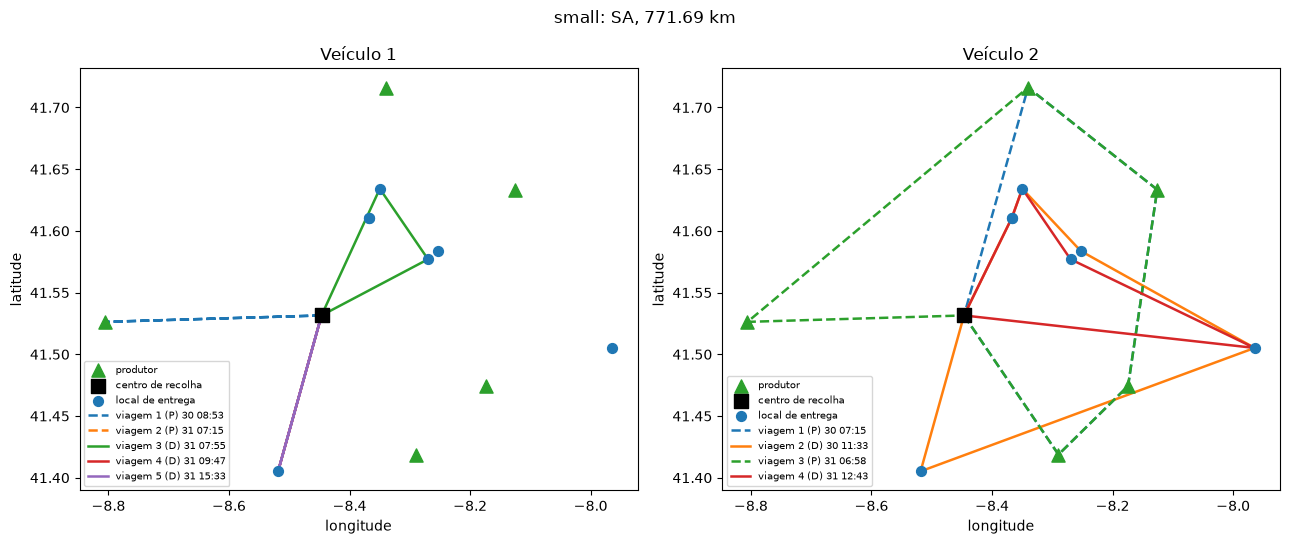

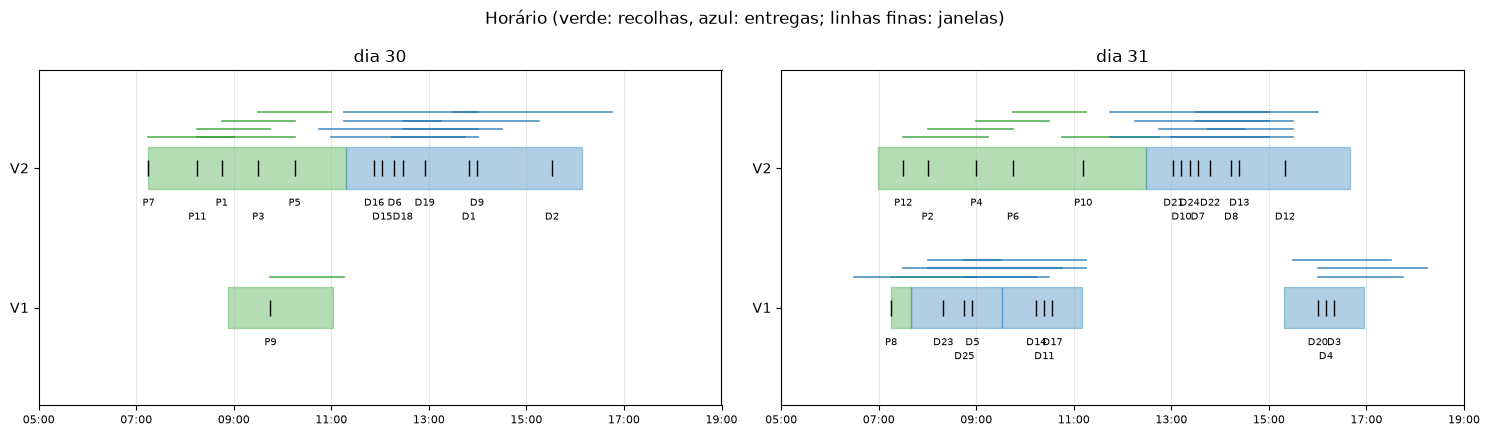

In [10]:
candidates = [(result.cost, f"HC {variant}", result.solution) for (name, variant), result in hill_climbs.items()
              if name == "small" and result.feasible]
candidates.append((annealing["small"].cost, "SA", annealing["small"].solution))
_, best_label, best_solution = min(candidates, key=lambda candidate: candidate[0])
best_eval = evaluate(small, best_solution)
print(best_label, best_eval.summary(), "| verificador:", check_solution(small, best_eval).valid)
plot_routes(small, best_solution, f"small: {best_label}, {best_eval.km:.2f} km");
plot_gantt(small, best_eval);

## 7. Conclusões

No tiny, o HC e o SA chegam ao ótimo. No small, ficam presos acima dele, e o resultado do SA depende muito dos parâmetros e da semente. Uma boa solução inicial ajuda.